# Laboratorio #10 — Explainable AI sobre SeñaBusca

**CC3092 · Deep Learning y Sistemas Inteligentes** — Universidad del Valle de Guatemala
**Esteban Cárcamo (23016) · Nicolás Concuá (23197)** — noviembre de 2026

Enlace al repositorio: https://github.com/nicoCT04/ProyectoFinal-DL

Explicamos el modelo **v2** del proyecto final (Transformer con transfer learning, `it7_tl_tf_webcam_s1`,
el que usa la app según `models/despliegue.json`) **sin reentrenarlo**. Este notebook regenera todas las
figuras y tablas del informe con semilla fija; el trabajo pesado está en `xai/generar_xai.py` y las
funciones en `xai/xai_asl.py`.

## 1. Investigación: métodos de XAI para nuestro tipo de dato

Cada seña es una **serie de tiempo multivariada**: 64 cuadros × 161 variables (53 puntos de MediaPipe en
x, y, z normalizados a los hombros + 2 banderas de presencia de mano).

| Método | Idea | Requiere | Costo | Limitaciones |
|---|---|---|---|---|
| Saliencia / SmoothGrad [1] | gradiente de la clase respecto a la entrada (promediado con ruido) | gradientes | 1 o n pasadas | ruidoso, saturación |
| **Integrated Gradients** [2] | integra el gradiente de una línea base a la entrada | gradientes + línea base | n pasos (64) | depende de la línea base |
| SHAP (Kernel, Gradient, Deep) [3] | valores de Shapley sobre variables o grupos | caja negra o gradientes + fondo | Kernel: miles de evaluaciones | caro, depende del fondo |
| LIME / Anchors [4] | modelo lineal (o regla) local en un vecindario perturbado | caja negra | cientos-miles de evaluaciones | inestable, sensible al kernel |
| Oclusión por ventanas [5] | reemplazar bloques parte × tiempo y medir la caída | caja negra | 1 pasada por bloque | fuera de distribución, sin interacciones |
| TimeSHAP, Dynamask, WinIT [6–8] | SHAP por eventos, máscaras aprendidas, ventanas | variable | de medio a alto | pensados para otros modelos o caros |
| Atención [CLS] | pesos de atención del Transformer | nada | gratis | no es una explicación fiel [9] |
| Grad-CAM | mapas de activación convolucionales | capas conv | bajo | **no aplica** (no hay convoluciones) |

* **Interpretable por diseño vs. a posteriori:** la regresión logística del proyecto es interpretable por
  sus coeficientes; IG explica a posteriori un modelo opaco. Usamos la logística como baseline de comparación.
* **Propiedades formales:** IG cumple *completitud* (Σ atribuciones = f(x) − f(x′)), sensibilidad e
  invariancia a la implementación; SHAP, aditividad/eficiencia; LIME, solo fidelidad local.
* **Parámetros que afectan la explicación:** línea base y pasos de IG, objetivo (logit o probabilidad),
  fondo de SHAP, kernel de LIME, tamaño y reemplazo de los bloques de oclusión, y la agregación.

## 2. Selección del método

| Criterio | Integrated Gradients (**elegido**) | Oclusión por bloques (alternativa) |
|---|---|---|
| Compatibilidad | modelo diferenciable en PyTorch, captum directo | cualquier modelo |
| Tipo de explicación | atribución con signo por punto y cuadro | caída de probabilidad por 32 bloques |
| Costo | ~100 ms por seña (CPU, 1 hilo) | ~30 ms por seña |
| Comunicación | mano y momento sobre el esqueleto | fácil, pero de baja resolución |
| Limitaciones | depende de la línea base | reemplazo fuera de distribución |

KernelSHAP por bloques se descartó por costo (≈ 2 000 evaluaciones por seña). La oclusión se calcula
de todas formas para **comparar la fidelidad** de ambos métodos (sección 3.4).

## 3. Implementación

### 3.0 Entorno y semilla

In [1]:
import json, sys, time
from pathlib import Path
import numpy as np, pandas as pd, torch
from IPython.display import Image, display

# Rutas robustas: funciona desde la raíz del repo o desde xai/
ROOT = Path.cwd() if (Path.cwd() / "asl").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "xai")); sys.path.insert(0, str(ROOT))
import xai_asl as X
import generar_xai as G
from asl.data import cargar_grupo

SEED = X.SEED                      # 23197
G.fijar_semillas()                 # numpy + torch, CPU con 1 hilo, algoritmos deterministas
REGENERAR = True                   # False = solo mostrar lo que ya está en reports/xai/
OUT = X.OUT
print("semilla:", SEED, "· salida:", OUT.relative_to(ROOT))

semilla: 23197 · salida: reports/xai


### 3.1 Modelo y datos

Se carga el mismo archivo y umbral que usa la app. No se reentrena nada.

In [2]:
m, clases, info = X.cargar_modelo("v2")
data, _ = cargar_grupo("objetivo")
Xte, yte, pte, _ = data["test"]
P = X.probabilidades(m, Xte); pred = P.argmax(1)
print(info)
print(f"prueba: {len(yte)} videos de {len(set(pte))} personas · top-1 = {(pred == yte).mean():.3f}")

{'archivo': 'it7_tl_tf_webcam_s1', 'desc': 'v2 · Transformer con transfer learning', 'umbral': 0.67, 'iteracion': 'it7_tl_tf_webcam', 'seed': 1}
prueba: 616 videos de 11 personas · top-1 = 0.906


### 3.2 Integrated Gradients en una seña: la línea base y la completitud

La línea base **«reposo»** es la misma persona con la pose promediada en el tiempo y **sin manos
detectadas** (coordenadas 0 y bandera 0, igual que codifica el preprocesamiento una mano ausente).
Comprobamos la completitud: la suma de atribuciones debe ser el logit de la seña menos el de la línea base.

In [3]:
i = 0
x = Xte[i:i + 1]; t = pred[i:i + 1]
b = X.linea_base(x, "reposo")
A, delta = X.integrated_gradients(m, x, t, b, n_steps=64)
with torch.no_grad():
    lx = m(torch.from_numpy(x))[0, t[0]].item(); lb = m(torch.from_numpy(b))[0, t[0]].item()
print(f"seña: {clases[yte[i]]} · predicción: {clases[t[0]]}")
print(f"Σ atribuciones = {A.sum():.4f}   logit(x) − logit(base) = {lx - lb:.4f}   error = {abs(delta[0]):.1e}")
print("cuota por parte:", dict(zip(X.GRUPOS_IG, np.round(np.abs(X.agregar(A)).sum(2)[0] / np.abs(X.agregar(A)).sum(), 3))))

seña: STUDENT · predicción: STUDENT
Σ atribuciones = 6.4556   logit(x) − logit(base) = 6.4556   error = 0.0e+00
cuota por parte: {'cara': np.float32(0.025), 'brazos': np.float32(0.147), 'mano izq.': np.float32(0.337), 'mano der.': np.float32(0.367), 'presencia de mano': np.float32(0.124)}


### 3.3 Corrida completa (todas las figuras y tablas del informe)

`G.main()` calcula IG con tres líneas base sobre los 616 videos de prueba, la oclusión, las curvas de
borrado, la prueba de cordura, el baseline interpretable (logística), los casos locales y el análisis de
señas fuera del vocabulario. Tarda ≈ 6 min en CPU.

In [4]:
if REGENERAR:
    t0 = time.time(); G.main(); print(f"listo en {time.time() - t0:.0f} s")
R = json.loads((OUT / "resumen.json").read_text())
pd.read_csv(OUT / "tabla_parametros.csv")

v2 top-1 prueba = 0.906  (58 errores de 616)


{
 "top1": 0.9058441558441559,
 "n_test": 616,
 "n_errores": 58,
 "umbral": 0.67,
 "top1_logistica": 0.6168831168831169,
 "costo_ms": {
  "inferencia_ms": 0.8356457983609289,
  "ig_ms": 99.13425415288657,
  "oclusion_ms": 27.932485449127853
 },
 "segundos_oclusion_total": 11.02715277671814,
 "auc_borrado": {
  "IG (reposo)": 0.18038888275623322,
  "IG (ceros)": 0.24656561017036438,
  "IG (media)": 0.261508584022522,
  "Oclusión": 0.350786030292511,
  "Azar": 0.5515555143356323
 },
 "spearman_ig_oclusion_mediana": 0.4783724340175953,
 "spearman_cordura_mediana": 0.011180351906158358,
 "cuota_global": {
  "cara": 0.030642475932836533,
  "brazos": 0.09748852998018265,
  "mano no dominante": 0.17534787952899933,
  "mano dominante": 0.5307676792144775,
  "presencia de mano": 0.1657535284757614
 },
 "cuota_logistica": {
  "cara": 0.07698935270309448,
  "brazos": 0.1445872038602829,
  "mano no dominante": 0.37127209290281515,
  "mano dominante": 0.39050942078813333,
  "presencia de mano": 0.0

,parametro,valor
0,Modelo,"v2 = it7_tl_tf_webcam_s1 (despliegue.json), si..."
1,Datos,prueba: 616 videos de 11 personas no vistas; O...
2,Método principal,Integrated Gradients (captum 0.9) sobre el log...
3,Línea base,reposo: misma pose promediada en el tiempo y m...
4,Pasos de integración,"64, regla de Gauss-Legendre"
5,Agregación,suma con signo por parte del cuerpo (5 grupos)...
6,Alternativa,oclusión de 4 partes × 8 ventanas de 8 cuadros...
7,Fidelidad,"curva de borrado de los 32 bloques, área bajo ..."
8,Semilla y entorno,"SEED = 23197; CPU, 1 hilo, algoritmos determin..."


### 3.4 Elección de la línea base y fidelidad (IG vs. oclusión)

,linea_base,segundos,err_completitud_max,prob_max_en_base,cuota cara,cuota brazos,cuota mano izq.,cuota mano der.,cuota presencia de mano
0,reposo,65.5,0.000170,0.646612,0.031,0.097,0.309,0.397,0.166
1,ceros,64.0,0.000006,0.533668,0.266,0.230,0.177,0.207,0.121
2,media,63.6,0.000005,0.181228,0.071,0.173,0.279,0.409,0.067


,metodo,auc_borrado,ms_por_instancia_cpu
0,IG (reposo),0.180,99.1
1,IG (ceros),0.247,99.1
2,IG (media),0.262,99.1
3,Oclusión,0.351,27.9
4,Azar,0.552,0.0


ρ Spearman IG vs oclusión (mediana): 0.48 · IG vs modelo con pesos al azar: 0.01


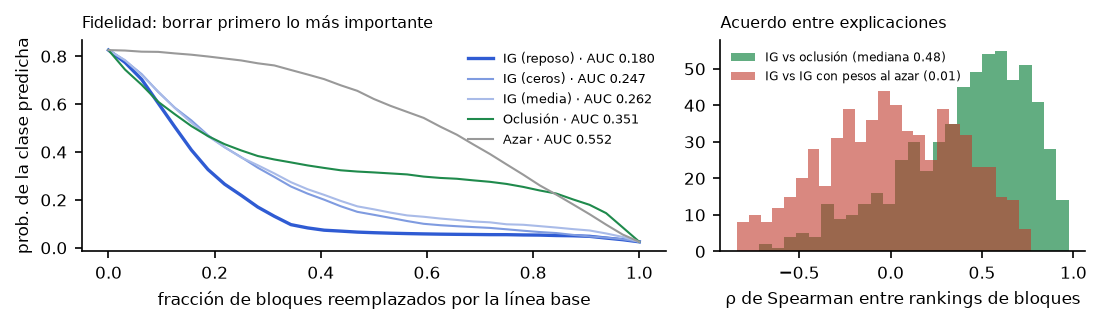

In [5]:
display(pd.read_csv(OUT / "tabla_lineas_base.csv"))
display(pd.read_csv(OUT / "tabla_metodos.csv"))
print("ρ Spearman IG vs oclusión (mediana):", round(R["spearman_ig_oclusion_mediana"], 2),
      "· IG vs modelo con pesos al azar:", round(R["spearman_cordura_mediana"], 2))
display(Image(OUT / "fig_fidelidad.png"))

La curva de borrado reemplaza primero los bloques que cada método marca como más importantes: si la
probabilidad cae rápido, la explicación es fiel. **IG con línea base de reposo** tiene la menor área
(la mitad que la oclusión). Con pesos aleatorios, el ranking de IG cambia por completo (ρ ≈ 0): la
explicación depende de lo aprendido y pasa la prueba de cordura.

### 3.5 Explicaciones locales (6 casos de prueba)

,caso,persona,real,real_es,pred,pred_es,confianza,top3,acepta_umbral,cuota cara,cuota brazos,cuota mano izq.,cuota mano der.,cuota presencia de mano,cuadro_pico,evidencia_neta_pred,evidencia_neta_real,parte_que_mas_separa
0,"Acierto, alta confianza",P47,STUDENT,estudiante,STUDENT,estudiante,0.986,STUDENT 0.99 · LEARN 0.00 · TEACHER 0.00,True,0.04,0.11,0.28,0.38,0.19,31,NaN,NaN,NaN
1,Error con más confianza,P35,HOT,caliente,BAD,malo,0.977,BAD 0.98 · HOT 0.00 · KNOW 0.00,True,0.05,0.11,0.00,0.66,0.18,20,3.24,3.89,brazos
2,Error del par más confundido,P48,GOOD,bueno,THANKYOU,gracias,0.813,THANKYOU 0.81 · GOOD 0.06 · HOT 0.02,True,0.03,0.11,0.10,0.69,0.08,46,8.49,6.77,mano der.
3,Cerca del umbral (0.67),P17,HAPPY,feliz,GOOD,bueno,0.669,GOOD 0.67 · HAPPY 0.25 · THANKYOU 0.03,False,0.04,0.16,0.64,0.00,0.16,22,8.32,5.39,presencia de mano
4,Subgrupo: mano izq. dominante,P6,WHERE,¿dónde?,WHERE,¿dónde?,0.919,WHERE 0.92 · NO 0.03 · BOOK 0.00,True,0.03,0.08,0.75,0.00,0.14,49,NaN,NaN,NaN
5,Fuera del vocabulario (aceptada),P47,SSHH,NaN,WHO,¿quién?,0.975,WHO 0.98 · SISTER 0.00 · TOMORROW 0.00,True,0.01,0.05,0.29,0.61,0.05,50,NaN,NaN,NaN


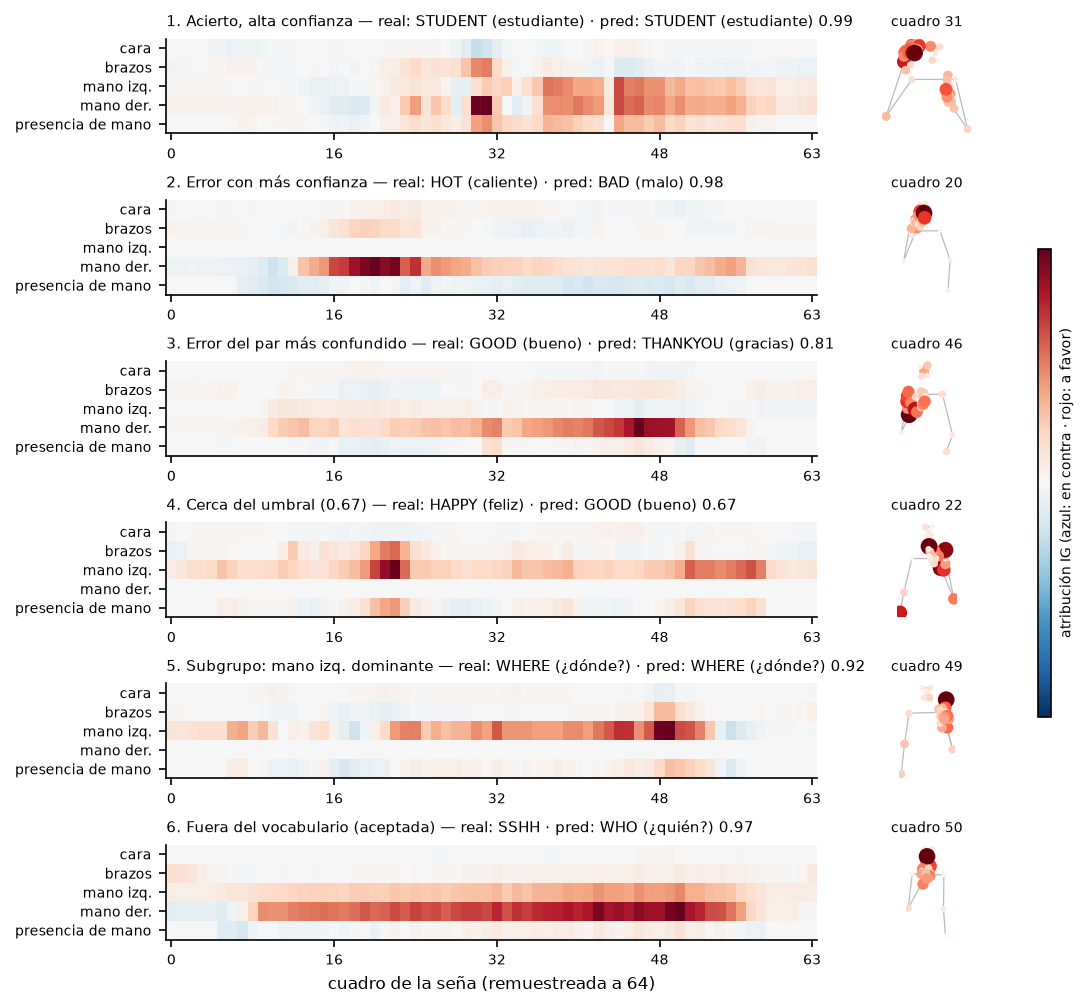

In [6]:
display(pd.read_csv(OUT / "tabla_casos_locales.csv"))
display(Image(OUT / "fig_casos_locales.png"))

### 3.6 Explicación global y baseline interpretable

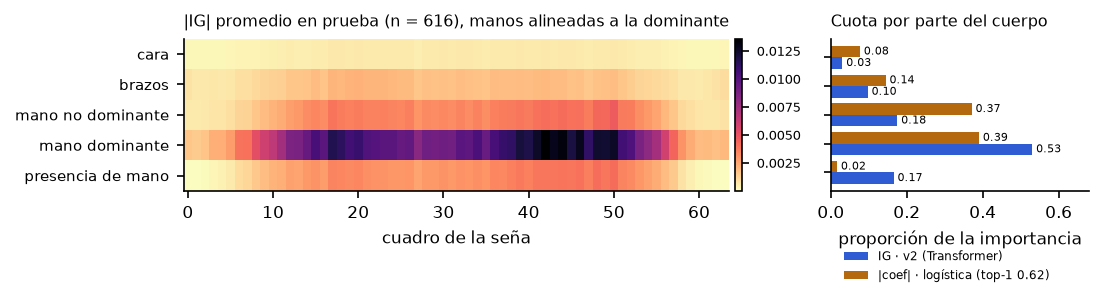

,IG v2,logística
cara,0.031,0.077
brazos,0.097,0.145
mano no dominante,0.175,0.371
mano dominante,0.531,0.391
presencia de mano,0.166,0.017


In [7]:
display(Image(OUT / "fig_global.png"))
pd.DataFrame({"IG v2": R["cuota_global"], "logística": R["cuota_logistica"]}).round(3)

## 4. Interpretación en el contexto del proyecto

In [8]:
pd.read_csv(OUT / "tabla_atajos_subgrupos.csv")

,grupo,n,top1,cuota_cara,cuota_brazos,cuota_mano_dominante,cuota_mano_no_dominante,cuota_presencia,cuota_bordes_16_cuadros
0,todas,616,0.906,0.031,0.097,0.531,0.175,0.166,0.084
1,aciertos,558,1.000,0.030,0.096,0.529,0.177,0.167,0.082
2,errores,58,0.000,0.037,0.112,0.546,0.156,0.149,0.110
3,mano der. dominante,360,0.911,0.031,0.095,0.547,0.167,0.160,0.090
4,mano izq. dominante,256,0.898,0.030,0.101,0.508,0.187,0.174,0.076


* **Señales con sentido:** la mano dominante concentra ~53 % de la atribución, la no dominante ~18 %, los
  brazos ~10 % y la cara ~3 %, en el tramo central de la seña. Coincide con la fonología de ASL (forma,
  ubicación y movimiento de la mano).
* **Atajos buscados:** identidad por la cara (3 %, no), lateralidad (41.6 % de señas con mano izquierda
  dominante; top-1 0.898 vs 0.911 y el modelo usa la mano dominante en ambos grupos), bordes del recorte
  (11 % en errores vs 8 % en aciertos). **Hallazgo:** las banderas de presencia de mano reciben ~17 %. Es un
  proxy de la calidad del detector: si MediaPipe pierde la mano, la predicción cambia.
* **Errores:** HOT → BAD y GOOD → THANKYOU comparten ubicación (boca/mentón) y dirección. Las distingue la
  forma de la mano o el contacto con la mano no dominante, que el modelo casi no usa. SSHH (fuera del
  vocabulario) → WHO por el índice junto a los labios.
* **Decisiones:** aumento que apague la detección de una mano por tramos, variable de distancia entre
  manos, regla de pares confundibles en la app y una clase «otra seña».
* **Para el usuario:** botón «¿por qué?» con el esqueleto y la parte decisiva resaltada, más una frase.

In [9]:
print(f"señas fuera del vocabulario aceptadas sobre el umbral: {R['oov_aceptadas']:.1%} de {R['n_oov']}")
print(f"errores con confianza sobre el umbral: {R['errores_con_conf_sobre_umbral']:.1%}")
print("pares más confundidos:", R["pares_confusion"])

señas fuera del vocabulario aceptadas sobre el umbral: 16.8% de 5451
errores con confianza sobre el umbral: 22.4%
pares más confundidos: {'PLEASE → HAPPY': 4, 'GOOD → THANKYOU': 4, 'THANKYOU → GOOD': 4, 'BAD → GOOD': 3, 'SISTER → BROTHER': 3, 'HOT → BAD': 2}


## 5. Discusión

* **IG vs. oclusión:** mantendríamos IG (más fiel, completitud y resolución de punto y cuadro); la línea
  base es la decisión que más cambia la fidelidad (con la salvedad de que la curva borra con la base de
  reposo, lo que favorece a IG-reposo frente a «ceros» y «media»).
* **Lo que no mostraban las métricas:** la dependencia de la presencia de mano y el poco uso de la mano no
  dominante en pares que dependen de ella.
* **Costo:** ~100 ms por seña contra ~1 ms de la inferencia: viable a demanda o por lote para auditoría.
* **Riesgos:** falsa confianza en explicaciones de errores con confianza alta; IG no explica los sesgos de
  MediaPipe; no usar para interpretación médica o legal, ni para calificar a estudiantes.

### Referencias
[1] Smilkov et al., 2017 · [2] Sundararajan et al., 2017 · [3] Lundberg y Lee, 2017 · [4] Ribeiro et al., 2016 ·
[5] Zeiler y Fergus, 2014 · [6] Bento et al., 2021 · [7] Crabbé y van der Schaar, 2021 · [8] Leung et al., 2023 ·
[9] Jain y Wallace, 2019 · [10] Samek et al., 2017 · [11] Adebayo et al., 2018 · [12] Kokhlikyan et al., 2020